### **Time series**

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from pandas_datareader import data
from statsmodels.datasets import sunspots
from datetime import datetime, timedelta

### Sunspot Activity

In [2]:
df_sun = sunspots.load_pandas().data
df_sun.YEAR = df_sun.YEAR.astype(int)
df_sun.set_index("YEAR", inplace=True)
df_sun.head()

,SUNACTIVITY
YEAR,
1700,5.0
1701,11.0
1702,16.0
1703,23.0
1704,36.0


- შეამოწმეთ, სტაციონარულია თუ არა ეს time series:
    - ვიზუალურად: არ უნდა იჩანდეს ტრენდი ან ცვალებადი მერყეობა
    - სტატისტიკურად: საშუალო, ვარიაცია, ADF ტესტი (Augmented Dickey-Fuller)
- აქვს თუ არა დროის სერიას მნიშვნელოვანი ავტოკორელაცია, ააგეთ ACF გრაფიკი, რომელ Lag-ზე გვაქვს მაღალი მნიშვნელობა?

### Federal Reserve Economic Data

In [8]:
# Consumer Price Index for All Urban Consumers
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"
df_cons = pd.read_csv(url)
df_cons = df_cons.set_index("observation_date")
df_cons.head()

,CPIAUCNS
observation_date,
1913-01-01,9.8
1913-02-01,9.8
1913-03-01,9.8
1913-04-01,9.8
1913-05-01,9.7


#### ARIMA
- დაყავით მონაცემები, 2024 წლამდე მონაცემები გამოიყენეთ როგორც Train სიმრავლე, დარჩენილი მონაცემები კი როგორც Test სიმრავლე
- ჩაატარეთ ADF ტესტი, საჭიროა თუ არა დროის სერიის დიფერენცირება?
- ააგეთ ACF, PACF გრაფიკები
- წინა ორ ნაბიჯზე დაყრდნობით აარჩიეთ d, p, q პარამეტრები ARIMA მოდელისთვის
- გაწვრთენით მოდელი სატრენინგო სიმრავლეზე, გააკეთეთ პროგნოზი სატესტო სიმრავლეზე
- შეადარეთ პროგნოზი ნამდვილ მნიშვნელობებს

### Open Power System Data (Electricity consumption)

In [4]:
# მონაცემების ჩატვირთვა
df_electricity = pd.read_csv("../../datasets/electricity/oppd.csv")
df_electricity.set_index("Date", inplace=True)
df_electricity.index = pd.to_datetime(df_electricity.index)
df_electricity.head()

,Consumption
Date,
2015-01-01,45346.541667
2015-01-02,51941.166667
2015-01-03,46564.750000
2015-01-04,45082.500000
2015-01-05,55246.666667


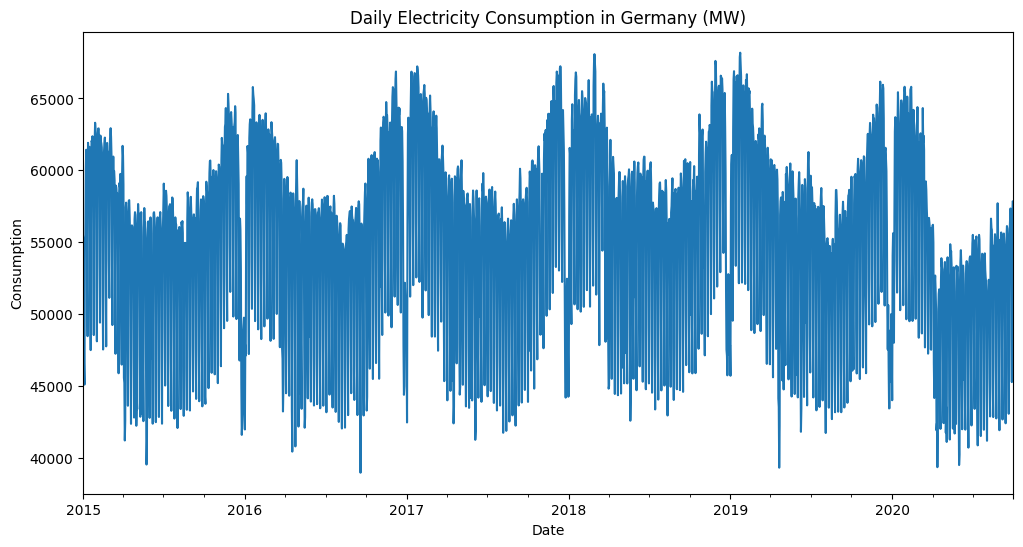

In [5]:
plt.figure(figsize=(12, 6))
df_electricity["Consumption"].plot()
plt.title("Daily Electricity Consumption in Germany (MW)")
plt.ylabel("Consumption")
plt.xlabel("Date")
plt.show()

#### XGBRegressor
- დაამატეთ Lag-Features 
- დაყავით მონაცემები:
    - 2020-06-01-მდე მონაცემები გამოიყენეთ როგორც Train სიმრავლე, 
    - დარჩენილი მონაცემები კი როგორც Test სიმრავლე
- გაწვრთენით XGBRegressor მოდელი training მონაცემებზე
- გააკეთეთ პროგნოზი testing მონაცემებზე
- მოახდინეთ მოდელის ევალუაცია